# 03 · Transition Rules and State-Aware Models

Notebook 02 found four behavioral states (Inactive, Light, Stock-up, Frequent), showed that customers move between them often, and that
much of that movement happens close to state boundaries. This notebook asks two modeling questions:

- **§E — Transition rules:** can *simple, readable conditions on original features* say when a customer will switch state?
- **§F — Reliability under state change:** are purchase predictions less reliable for customers whose state just changed, and does
  making the model state-aware help?
- **§H — Bridge to formal state-transition modeling:** what this empirical system is, and what it is not.

Inputs: `model_data.parquet`, `customer_period.parquet`, `customer_states.parquet` (notebooks 01–02). Same customer split as before
(60/20/20, `random_state=42`): models are fit on **train**, choices are made on **validation**, and **test** is used once for final numbers.

## Setup

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.metrics import roc_auc_score, accuracy_score, balanced_accuracy_score, confusion_matrix

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

DATA_DIR = Path("../data/processed")
FIG_DIR = Path("../figures")
FIG_DIR.mkdir(exist_ok=True)

PERIODS = ["E1", "E2", "E3", "E4"]
PERIOD_PAIRS = [("E1", "E2"), ("E2", "E3"), ("E3", "E4")]
ACTIVE_STATES = ["Light", "Stock-up", "Frequent"]
STATE_ORDER = ["Inactive"] + ACTIVE_STATES

model_data = pd.read_parquet(DATA_DIR / "model_data.parquet").set_index("client_id")
states = pd.read_parquet(DATA_DIR / "customer_states.parquet").set_index("client_id")
period_lines = (pd.read_parquet(DATA_DIR / "customer_period.parquet", columns=["client_id", "period", "category_lines"])
                  .pivot(index="client_id", columns="period", values="category_lines"))

print("Customers with states:", len(states))
states["split"].value_counts()

Customers with states: 177600


split
train    106621
val       35549
test      35430
Name: count, dtype: int64

## §E · Interpretable transition conditions

**Unit:** one row per customer per transition t → t+1, for customers **active in both periods** (Light / Stock-up / Frequent → same set).
Transitions into or out of Inactive are left out here: E4 contains no Inactive customers, so rules involving Inactive could not be tested on E3→E4.

**Two framings — they answer different questions and must not be confused:**

1. **Descriptive guards** use information from *both* t and t+1 (how features changed). They describe what a transition *looked like*.
   Because states are defined from these same features, a tree will mostly rediscover the KMeans boundaries. High accuracy here is expected and
   proves little; it is shown to make the circularity visible.
2. **Predictive conditions** use only information available at time t: current state, current behavior, distance to the state boundary
   (margin), and observation depth. They ask what, *before* a switch, signals that one is coming. This is the scientifically interesting version.

**Model:** `DecisionTreeClassifier`, deliberately shallow. A tree splits the data with one yes/no question at a time
(e.g. "transactions ≤ 2?") and each final leaf is a rule. Depth is chosen on validation; `min_samples_leaf=1000` stops tiny, unreliable leaves.
Trees are unaffected by monotone transformations, so features are kept in **original units** and the printed thresholds are readable.

**Time-based check:** trees are fit on E1→E2 and E2→E3 transitions (train customers) and then evaluated on the *later* E3→E4 transition.
If the rules still work there, they are stable over time — a basic requirement for a transition guard.

In [2]:
FEATURES_T = ["transactions", "avg_basket_spend", "avg_unique_products", "total_spend"]

rows = []
for a, b in PERIOD_PAIRS:
    df = pd.DataFrame(index=states.index)
    df["transition"] = f"{a}→{b}"
    df["split"] = states["split"]
    df["state_t"], df["state_t1"] = states[f"state_{a}"], states[f"state_{b}"]
    df["margin_t"] = states[f"margin_{a}"]
    for f in FEATURES_T:
        df[f] = model_data.loc[states.index, f"{f}_{a}"]
        df[f"{f}_next"] = model_data.loc[states.index, f"{f}_{b}"]
    df["category_lines"] = period_lines.loc[states.index, a]
    rows.append(df.reset_index())

transitions = pd.concat(rows, ignore_index=True)
transitions = transitions[transitions["state_t"].isin(ACTIVE_STATES) & transitions["state_t1"].isin(ACTIVE_STATES)].copy()
transitions["switched"] = (transitions["state_t"] != transitions["state_t1"]).astype(int)
for s in ACTIVE_STATES:
    transitions[f"is_{s}"] = (transitions["state_t"] == s).astype(int)
for f in ["transactions", "avg_basket_spend", "avg_unique_products"]:
    transitions[f"change_{f}"] = np.log1p(transitions[f"{f}_next"]) - np.log1p(transitions[f])

is_fit = transitions["transition"] != "E3→E4"
SETS = {
    "train (E1→E2, E2→E3)": transitions[(transitions["split"] == "train") & is_fit],
    "val (E1→E2, E2→E3)":   transitions[(transitions["split"] == "val") & is_fit],
    "val (E3→E4)":          transitions[(transitions["split"] == "val") & ~is_fit],
    "test (E1→E2, E2→E3)":  transitions[(transitions["split"] == "test") & is_fit],
    "test (E3→E4)":         transitions[(transitions["split"] == "test") & ~is_fit],
}
pd.DataFrame({name: {"rows": len(d), "switch_rate": d["switched"].mean()} for name, d in SETS.items()}).T.round(3)

,rows,switch_rate
"train (E1→E2, E2→E3)",166298.0,0.363
"val (E1→E2, E2→E3)",55632.0,0.363
val (E3→E4),31147.0,0.353
"test (E1→E2, E2→E3)",55250.0,0.372
test (E3→E4),30989.0,0.356


### E.1 · Descriptive guards (uses t+1 information — circular by design)

Predict the next state from the current state plus how trips, basket size and variety changed.

In [3]:
DESC_FEATURES = [f"is_{s}" for s in ACTIVE_STATES] + FEATURES_T[:3] + \
                ["change_transactions", "change_avg_basket_spend", "change_avg_unique_products"]
train_fit, val_fit = SETS["train (E1→E2, E2→E3)"], SETS["val (E1→E2, E2→E3)"]

desc_tree = DecisionTreeClassifier(max_depth=4, min_samples_leaf=1000, random_state=0)
desc_tree.fit(train_fit[DESC_FEATURES], train_fit["state_t1"])
pred = desc_tree.predict(val_fit[DESC_FEATURES])
print(f"Descriptive tree (depth 4, {desc_tree.get_n_leaves()} leaves) — validation accuracy: "
      f"{accuracy_score(val_fit['state_t1'], pred):.3f}, balanced accuracy: {balanced_accuracy_score(val_fit['state_t1'], pred):.3f}")
print(f"'Stay in the same state' baseline — accuracy: {accuracy_score(val_fit['state_t1'], val_fit['state_t']):.3f}")

Descriptive tree (depth 4, 16 leaves) — validation accuracy: 0.751, balanced accuracy: 0.739
'Stay in the same state' baseline — accuracy: 0.637


Knowing how behavior changed between t and t+1 identifies the next state far better than assuming no change — as expected, because the
states *are* regions of these features. These are valid descriptions of what transitions look like, but they cannot be used to anticipate a
transition, since they need the future period. From here on, only information available at time t is used.

### E.2 · Predictive conditions: *will* this customer switch state next month?

Target: `switched` (1 if the next active state differs). Features available at time t:

| Feature | Meaning |
|---|---|
| `is_Light`, `is_Stock-up`, `is_Frequent` | current state |
| `margin_t` | distance to the nearest state boundary (notebook 02 §C) |
| `transactions`, `avg_basket_spend`, `avg_unique_products`, `total_spend` | current-period behavior, original units |
| `category_lines` | number of product lines this period (observation depth) |

**Baselines:** (i) current state only — switch rates differ by state; (ii) margin only — closeness to a boundary.
The tree must beat both to show that the readable rules add information. **Metric:** AUC (probability that a random switcher
gets a higher predicted switch risk than a random stayer).

In [4]:
PRED_FEATURES = [f"is_{s}" for s in ACTIVE_STATES] + ["margin_t"] + FEATURES_T + ["category_lines"]

state_rate = train_fit.groupby("state_t")["switched"].mean()

def baseline_scores(df):
    return {"state only": df["state_t"].map(state_rate).to_numpy(),
            "margin only": -df["margin_t"].to_numpy()}

rows = []
for depth in [1, 2, 3, 4, 5, 6]:
    tree = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=1000, random_state=0)
    tree.fit(train_fit[PRED_FEATURES], train_fit["switched"])
    rows.append({"max_depth": depth, "leaves": tree.get_n_leaves(),
                 "val_AUC": roc_auc_score(val_fit["switched"], tree.predict_proba(val_fit[PRED_FEATURES])[:, 1])})
depth_table = pd.DataFrame(rows)
for name, score in baseline_scores(val_fit).items():
    print(f"Baseline '{name}': validation AUC {roc_auc_score(val_fit['switched'], score):.3f}")
depth_table.round(3)

Baseline 'state only': validation AUC 0.574
Baseline 'margin only': validation AUC 0.649


,max_depth,leaves,val_AUC
0,1,2,0.614
1,2,4,0.665
2,3,8,0.683
3,4,16,0.689
4,5,31,0.695
5,6,51,0.699


Depth 3 (8 rules) is chosen: AUC rises quickly up to depth 3 and only slowly after (depth 6 needs ~50 rules for about +0.016).
Few readable rules are worth more here than a small accuracy gain.

In [5]:
switch_tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=1000, random_state=0)
switch_tree.fit(train_fit[PRED_FEATURES], train_fit["switched"])

def tree_rules(tree, feature_names):
    """Each leaf as a readable rule with its training size and switch rate."""
    t = tree.tree_
    rules = []
    def walk(node, conditions):
        if t.children_left[node] == -1:
            n = t.n_node_samples[node]
            rate = t.value[node][0][1] / t.value[node][0].sum()
            rules.append({"rule": " AND ".join(conditions) or "(all)", "train_rows": n, "switch_rate": rate})
            return
        f, thr = feature_names[t.feature[node]], t.threshold[node]
        if f.startswith("is_"):
            walk(t.children_left[node], conditions + [f"state ≠ {f[3:]}"])
            walk(t.children_right[node], conditions + [f"state = {f[3:]}"])
        else:
            walk(t.children_left[node], conditions + [f"{f} ≤ {thr:.2f}"])
            walk(t.children_right[node], conditions + [f"{f} > {thr:.2f}"])
    walk(0, [])
    return pd.DataFrame(rules).sort_values("switch_rate", ascending=False).reset_index(drop=True)

rules = tree_rules(switch_tree, PRED_FEATURES)
with pd.option_context("display.max_colwidth", 120):
    display(rules.round(3))

,rule,train_rows,switch_rate
0,margin_t ≤ 0.98 AND transactions ≤ 6.50 AND margin_t ≤ 0.51,34059,0.555
1,margin_t ≤ 0.98 AND transactions ≤ 6.50 AND margin_t > 0.51,24691,0.473
2,margin_t ≤ 0.98 AND transactions > 6.50 AND margin_t ≤ 0.37,7157,0.451
3,margin_t > 0.98 AND total_spend ≤ 1756.85 AND margin_t ≤ 1.94,29048,0.404
4,margin_t ≤ 0.98 AND transactions > 6.50 AND margin_t > 0.37,14763,0.307
5,margin_t > 0.98 AND total_spend ≤ 1756.85 AND margin_t > 1.94,4282,0.249
6,margin_t > 0.98 AND total_spend > 1756.85 AND category_lines ≤ 50.50,31041,0.227
7,margin_t > 0.98 AND total_spend > 1756.85 AND category_lines > 50.50,21257,0.101


In [6]:
# How well do the rules work, and do they keep working on the later E3→E4 transition?
rows = []
for name, d in SETS.items():
    if name.startswith("train"):
        continue
    r = {"evaluation set": name, "rows": len(d), "switch_rate": d["switched"].mean(),
         "tree_AUC": roc_auc_score(d["switched"], switch_tree.predict_proba(d[PRED_FEATURES])[:, 1])}
    for b, score in baseline_scores(d).items():
        r[f"{b}_AUC"] = roc_auc_score(d["switched"], score)
    rows.append(r)
rule_eval = pd.DataFrame(rows)
rule_eval.round(3)

,evaluation set,rows,switch_rate,tree_AUC,state only_AUC,margin only_AUC
0,"val (E1→E2, E2→E3)",55632,0.363,0.683,0.574,0.649
1,val (E3→E4),31147,0.353,0.682,0.586,0.642
2,"test (E1→E2, E2→E3)",55250,0.372,0.685,0.576,0.652
3,test (E3→E4),30989,0.356,0.687,0.591,0.646


### E.3 · Predicting the destination state

Can information at time t predict *which* state comes next, better than "stays in the same state"? Here the target is the next state itself.

In [7]:
DEST_FEATURES = PRED_FEATURES
rows = []
for depth in [2, 3, 4, 6]:
    dt = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=1000, random_state=0)
    dt.fit(train_fit[DEST_FEATURES], train_fit["state_t1"])
    p = dt.predict(val_fit[DEST_FEATURES])
    rows.append({"model": f"tree depth {depth}", "accuracy": accuracy_score(val_fit["state_t1"], p),
                 "balanced_accuracy": balanced_accuracy_score(val_fit["state_t1"], p)})
rows.append({"model": "stay in current state", "accuracy": accuracy_score(val_fit["state_t1"], val_fit["state_t"]),
             "balanced_accuracy": balanced_accuracy_score(val_fit["state_t1"], val_fit["state_t"])})
pd.DataFrame(rows).round(3)

,model,accuracy,balanced_accuracy
0,tree depth 2,0.629,0.623
1,tree depth 3,0.630,0.605
2,tree depth 4,0.631,0.615
3,tree depth 6,0.636,0.625
4,stay in current state,0.637,0.626


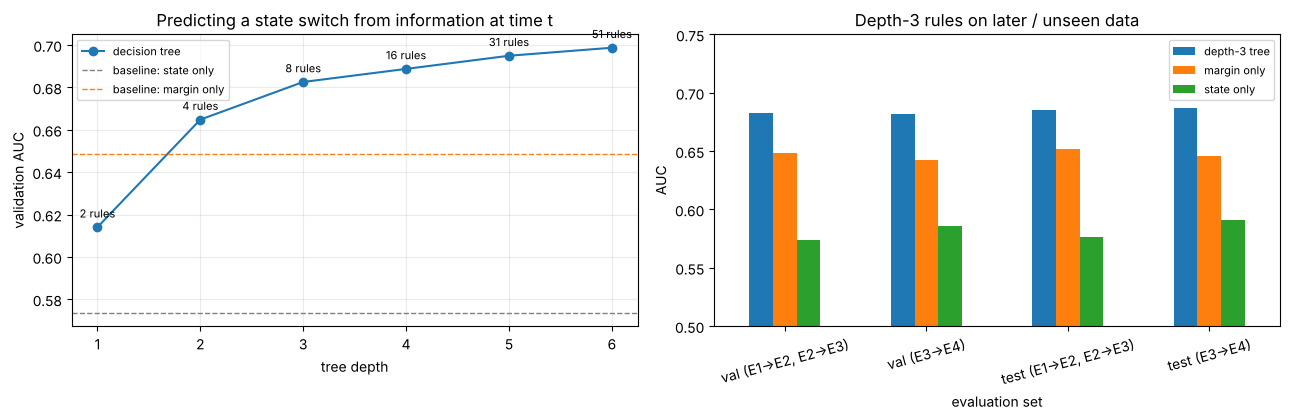

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))

d = depth_table
axes[0].plot(d["max_depth"], d["val_AUC"], marker="o", label="decision tree")
for name, score in baseline_scores(val_fit).items():
    axes[0].axhline(roc_auc_score(val_fit["switched"], score), ls="--", lw=1,
                    color="grey" if name == "state only" else "tab:orange", label=f"baseline: {name}")
for depth, leaves, auc_ in d[["max_depth", "leaves", "val_AUC"]].itertuples(index=False):
    axes[0].annotate(f"{leaves} rules", (depth, auc_), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8)
axes[0].set(xlabel="tree depth", ylabel="validation AUC", title="Predicting a state switch from information at time t")
axes[0].legend(fontsize=8); axes[0].grid(alpha=0.25)

re_ = rule_eval.set_index("evaluation set")[["tree_AUC", "margin only_AUC", "state only_AUC"]]
re_.plot.bar(ax=axes[1], rot=15)
axes[1].set(ylim=(0.5, 0.75), ylabel="AUC", title="Depth-3 rules on later / unseen data")
axes[1].legend(["depth-3 tree", "margin only", "state only"], fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / "E_transition_rules.png", dpi=130)
plt.show()

### §E · Interpretation

1. **Descriptive guards are easy and uninformative.** Using how behavior changed between t and t+1, a depth-4 tree identifies the next
   state with 75% accuracy vs 64% for "no change" — it is re-learning the KMeans boundaries. Useful as a description, useless as a forecast.
2. **Predictive rules are readable and modest.** With only information at time t, an 8-rule tree ranks future switchers with AUC ≈ 0.68,
   better than either baseline (current state: 0.57; boundary margin: 0.65). The rules span a 5× range of switch risk:
   - **Highest risk (≈ 55%):** close to a boundary (margin ≤ 0.51) and ≤ 6 trips this month.
   - **Lowest risk (≈ 10%):** deep inside a state (margin > 0.98), spending > ~1,760 this month, and > 50 product lines (well observed).
   The tree never uses the state labels themselves: trips and spend already carry that information, and the margin carries the rest.
3. **The rules transfer over time.** Learned on E1→E2 / E2→E3, they score the same on the later E3→E4 transition and on unseen test
   customers (AUC 0.68–0.69). The *conditions* under which customers switch did not drift over these four months.
4. **Where a customer goes next is not predictable from time-t information.** No tree beats "stays in the current state" (63.7% accuracy).
   Rules can say *who is at risk of moving*, not *where to*.

**What this means.** In this data, switch risk is mostly explained by two things: being near a state boundary and having little activity
(few trips / low spend / few lines). Both describe how *fragile* the current label is, not a behavioral cause. Combined with §C–§D, the honest
reading is that a large share of observed transitions is the measurement process (thresholds on small monthly counts) rather than customers
changing course — and the rules make that visible in plain conditions. That is exactly what interpretable transition guards are for.

**Not formal guards.** These are empirical, statistically estimated rules with error rates, learned from one dataset. They have no temporal-logic
semantics and no guarantee of consistency; making them formal and checkable is the subject of the Dortmund project (see §H).

**Limitations**
- Transitions involving Inactive are excluded (E4 selection makes them untestable on E3→E4).
- Thresholds such as `margin ≤ 0.98` come from one tree fit; nearby values would work almost as well. The *shape* of the rules is the result.
- AUC ≈ 0.68 means many individual switches remain unexplained by time-t information.

## §F · Reliability under state change: global vs state-aware models

**Question:** Are purchase predictions less reliable for customers whose behavioral state just changed — and does making the model aware of
states (or of recent behavior at all) reduce that?

**Prediction task:** will the customer purchase after the campaign (`target`)? **Control customers only** (not messaged), so the outcome
reflects natural purchasing and is not mixed with the effect of the message (the message is studied in notebook 04).
Enrolled cohort, same customer split: train ≈ 53K, validation ≈ 18K, test ≈ 18K control customers.

**Customer groups (by the last transition, E3 → E4):**
- **stable** — same state in E3 and E4;
- **changed** — a different *active* state in E3 and E4 (e.g. Stock-up → Frequent);
- **reactivated** — Inactive in E3, active in E4. Kept separate: every E3-inactive customer is active in E4 by construction of the sample.

**Models** (all logistic regression on standardized inputs unless stated; fit on train only):

| Model | Inputs | Idea |
|---|---|---|
| **History only** | E1–E3 averages, history depth | a "stale" profile that has not seen the latest month |
| **Global (current)** | E4 behavior + E1–E3 averages + depth | one model for everyone, sees recent behavior |
| **Global + state** | Global inputs + one-hot E3 state, E4 state, changed flag | state-aware, pooled |
| **Per-state** | Global inputs, separate model per E4 state | state-aware, separate parameters |
| **Global HGB** | Global inputs, gradient boosting | flexible reference: can learn interactions on its own |
| **GRU (PyTorch)** | the raw E1→E4 monthly sequence | learned sequence model: builds its own summary of the trajectory |

**Reliability metrics, per group:**
- **AUC** — ranking: does the model put buyers above non-buyers?
- **Log loss** — overall quality of the probabilities (lower = better).
- **Calibration gap** — mean predicted probability − actual purchase rate. 0 = calibrated; +0.10 = predicts 10 points too high.

All model comparisons are made on **validation**. **Test** is used once, at the end, with bootstrap confidence intervals.

In [9]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import log_loss, brier_score_loss

BEHAVIOR = ["transactions", "total_spend", "avg_basket_spend", "total_quantity", "avg_quantity", "avg_unique_products"]
HIST_BASE = ["transactions", "total_spend", "avg_basket_spend", "total_quantity"]

cust = states.join(model_data)
cust = cust[cust["treatment_flg"] == 0].copy()

for f in BEHAVIOR:
    cust[f"log_{f}_E4"] = np.log1p(cust[f"{f}_E4"])
for f in HIST_BASE:
    cust[f"log_{f}_hist"] = np.log1p(cust[f"{f}_historical_mean"])
cust["log_history_lines"] = np.log1p(cust["historical_category_lines"])

HISTORY_FEATURES = [f"log_{f}_hist" for f in HIST_BASE] + ["history_periods_active", "log_history_lines"]
CURRENT_FEATURES = [f"log_{f}_E4" for f in BEHAVIOR] + HISTORY_FEATURES
for s in ACTIVE_STATES:
    cust[f"E4_is_{s}"] = (cust["state_E4"] == s).astype(int)
for s in STATE_ORDER:
    cust[f"E3_is_{s}"] = (cust["state_E3"] == s).astype(int)
cust["changed"] = (cust["state_E3"] != cust["state_E4"]).astype(int)
STATE_FEATURES = [f"E4_is_{s}" for s in ACTIVE_STATES] + [f"E3_is_{s}" for s in STATE_ORDER] + ["changed"]

cust["group"] = np.select([cust["state_E3"] == "Inactive", cust["changed"] == 1], ["reactivated", "changed"], default="stable")
GROUPS = ["stable", "changed", "reactivated"]

ctrain, cval, ctest = (cust[cust["split"] == s] for s in ["train", "val", "test"])
print("Control customers — train:", len(ctrain), "| val:", len(cval), "| test:", len(ctest))
cval.groupby("group").agg(customers=("target", "size"), purchase_rate=("target", "mean")).assign(
    share=lambda d: d["customers"] / d["customers"].sum()).round(3)

Control customers — train: 53210 | val: 17760 | test: 17669


,customers,purchase_rate,share
group,,,
changed,5508,0.608,0.310
reactivated,2197,0.307,0.124
stable,10055,0.672,0.566


In [10]:
def logreg():
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))

class PerStateModel:
    """One logistic regression per E4 state."""
    def fit(self, df, features):
        self.features = features
        self.models = {s: logreg().fit(df.loc[df["state_E4"] == s, features], df.loc[df["state_E4"] == s, "target"])
                       for s in ACTIVE_STATES}
        return self
    def predict(self, df):
        p = np.zeros(len(df))
        for s, m in self.models.items():
            mask = (df["state_E4"] == s).to_numpy()
            p[mask] = m.predict_proba(df.loc[mask, self.features])[:, 1]
        return p

def fit_all(train_df):
    fitted = {
        "History only": (logreg().fit(train_df[HISTORY_FEATURES], train_df["target"]), HISTORY_FEATURES),
        "Global (current)": (logreg().fit(train_df[CURRENT_FEATURES], train_df["target"]), CURRENT_FEATURES),
        "Global + state": (logreg().fit(train_df[CURRENT_FEATURES + STATE_FEATURES], train_df["target"]),
                           CURRENT_FEATURES + STATE_FEATURES),
        "Per-state": (PerStateModel().fit(train_df, CURRENT_FEATURES), None),
        "Global HGB": (HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_leaf_nodes=15,
                                                      min_samples_leaf=100, random_state=0)
                       .fit(train_df[CURRENT_FEATURES], train_df["target"]), CURRENT_FEATURES),
    }
    return fitted

def predict_all(fitted, df):
    out = {}
    for name, (m, feats) in fitted.items():
        out[name] = m.predict(df) if feats is None else m.predict_proba(df[feats])[:, 1]
    return out

MODELS = fit_all(ctrain)
val_pred = predict_all(MODELS, cval)

### A learned sequence model: GRU in PyTorch

Every model above uses **hand-built summaries** of the history (E4 values, E1–E3 averages). A **recurrent neural network** instead reads the
four months *in order* and learns its own summary of the trajectory. This tests whether a learned temporal representation handles changed
customers better than simple features.

**How a GRU works (one sentence per piece):**
- The input is a sequence of 4 monthly vectors (6 behavior features + product-line count + an "active this month" flag, log-scaled and
  standardized with training statistics).
- The GRU keeps a small *hidden state* (16 numbers). Each month it reads the new vector and updates the hidden state, using learned
  *gates* that decide how much of the old summary to keep and how much to overwrite.
- After E4, a single linear layer turns the final hidden state into a purchase probability (sigmoid).
- Training minimizes log loss with the Adam optimizer on mini-batches; **early stopping** keeps the epoch with the best *validation* log loss
  (no test data involved).

It is deliberately small (≈ 1,300 parameters). Because neural network training depends on random initialization, it is trained with
5 different seeds to check that the result is stable.

In [11]:
import torch
from torch import nn

torch.set_num_threads(4)

def sequence_array(df):
    """customers × 4 periods × 8 features"""
    steps = []
    for p in PERIODS:
        cols = [np.log1p(df[f"{f}_{p}"].to_numpy()) for f in BEHAVIOR]
        cols.append(np.log1p(period_lines.loc[df.index, p].to_numpy()))
        cols.append((df[f"transactions_{p}"] > 0).to_numpy().astype(float))
        steps.append(np.column_stack(cols))
    return np.stack(steps, axis=1).astype(np.float32)

seq = {name: sequence_array(d) for name, d in [("train", ctrain), ("val", cval), ("test", ctest)]}
flat_train = seq["train"].reshape(-1, seq["train"].shape[2])
seq_mean, seq_std = flat_train.mean(axis=0), flat_train.std(axis=0)      # training statistics only
seq_t = {k: torch.tensor((v - seq_mean) / seq_std) for k, v in seq.items()}
print("Sequence tensor shapes:", {k: tuple(v.shape) for k, v in seq_t.items()})

class PurchaseGRU(nn.Module):
    def __init__(self, n_features, hidden=16):
        super().__init__()
        self.gru = nn.GRU(n_features, hidden, batch_first=True)
        self.head = nn.Linear(hidden, 1)
    def forward(self, x):
        _, h_last = self.gru(x)            # h_last: final hidden state after E4
        return self.head(h_last[-1]).squeeze(-1)   # logit

def train_gru(seed, max_epochs=40, patience=4, batch_size=512, lr=1e-3):
    torch.manual_seed(seed)
    model = PurchaseGRU(seq_t["train"].shape[2])
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.BCEWithLogitsLoss()
    y_train = torch.tensor(ctrain["target"].to_numpy(), dtype=torch.float32)
    y_val = cval["target"].to_numpy()
    best_loss, best_state, best_epoch, bad = np.inf, None, 0, 0
    for epoch in range(max_epochs):
        model.train()
        order = torch.randperm(len(y_train))
        for i in range(0, len(order), batch_size):
            idx = order[i:i + batch_size]
            opt.zero_grad()
            loss = loss_fn(model(seq_t["train"][idx]), y_train[idx])
            loss.backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            val_loss = log_loss(y_val, torch.sigmoid(model(seq_t["val"])).numpy())
        if val_loss < best_loss - 1e-4:
            best_loss, best_epoch, bad = val_loss, epoch, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                break
    model.load_state_dict(best_state)
    model.eval()
    return model, best_epoch

def gru_predict(model, split):
    with torch.no_grad():
        return torch.sigmoid(model(seq_t[split])).numpy()

rows, gru_models = [], {}
for seed in range(5):
    m, ep = train_gru(seed)
    gru_models[seed] = m
    p = gru_predict(m, "val")
    rows.append({"seed": seed, "best_epoch": ep, "val_AUC": roc_auc_score(cval["target"], p),
                 "val_log_loss": log_loss(cval["target"], p)})
gru_seeds = pd.DataFrame(rows)
print("Parameters:", sum(p.numel() for p in gru_models[0].parameters()))
display(gru_seeds.round(4))
print(f"Seed spread — AUC: {gru_seeds['val_AUC'].min():.4f}–{gru_seeds['val_AUC'].max():.4f}")

GRU = gru_models[0]      # seed 0 is used below; the spread above shows the choice does not matter
val_pred["GRU (PyTorch)"] = gru_predict(GRU, "val")

Sequence tensor shapes: {'train': (53210, 4, 8), 'val': (17760, 4, 8), 'test': (17669, 4, 8)}


Parameters: 1265


,seed,best_epoch,val_AUC,val_log_loss
0,0,15,0.7776,0.5486
1,1,19,0.7777,0.5484
2,2,10,0.7777,0.5487
3,3,10,0.7776,0.5488
4,4,12,0.7775,0.5488


Seed spread — AUC: 0.7775–0.7777


In [12]:
def metrics(y, p):
    return {"AUC": roc_auc_score(y, p), "log_loss": log_loss(y, p), "calibration_gap": p.mean() - y.mean()}

def by_group(df, preds):
    rows = []
    for name, p in preds.items():
        rows.append({"model": name, "group": "all", "n": len(df), **metrics(df["target"].to_numpy(), p)})
        for g in GROUPS:
            mask = (df["group"] == g).to_numpy()
            rows.append({"model": name, "group": g, "n": mask.sum(), **metrics(df["target"].to_numpy()[mask], p[mask])})
    return pd.DataFrame(rows)

val_results = by_group(cval, val_pred)
MODEL_ORDER = list(MODELS) + ["GRU (PyTorch)"]
for metric in ["AUC", "log_loss", "calibration_gap"]:
    print(f"\nValidation {metric}")
    display(val_results.pivot(index="model", columns="group", values=metric)
            .reindex(index=MODEL_ORDER, columns=["all"] + GROUPS).round(3 if metric != "log_loss" else 4))


Validation AUC


group,all,stable,changed,reactivated
model,,,,
History only,0.746,0.761,0.663,0.580
Global (current),0.776,0.780,0.716,0.677
Global + state,0.776,0.779,0.718,0.679
Per-state,0.776,0.779,0.717,0.677
Global HGB,0.776,0.780,0.717,0.678
GRU (PyTorch),0.778,0.781,0.718,0.684



Validation log_loss


group,all,stable,changed,reactivated
model,,,,
History only,0.5773,0.5371,0.6355,0.6153
Global (current),0.5502,0.5194,0.5977,0.5720
Global + state,0.5499,0.5196,0.5973,0.5697
Per-state,0.5506,0.5200,0.5977,0.5724
Global HGB,0.5500,0.5192,0.5976,0.5714
GRU (PyTorch),0.5486,0.5185,0.5967,0.5661



Validation calibration_gap


group,all,stable,changed,reactivated
model,,,,
History only,-0.000,-0.009,0.001,0.037
Global (current),-0.000,-0.005,-0.000,0.021
Global + state,0.000,0.003,-0.006,0.003
Per-state,0.000,-0.002,-0.004,0.022
Global HGB,-0.000,-0.004,-0.003,0.025
GRU (PyTorch),0.001,-0.000,0.003,0.005


**First reading (validation).** All models that see the current month (E4) perform almost identically, overall and in every group:
explicit state information — pooled or per-state — adds nothing measurable, and neither does a flexible boosted model. The GRU is
marginally better (AUC +0.002, log loss −0.0016) and, like the state-aware model, removes the over-prediction for reactivated customers.
Changed and reactivated customers *look* harder to predict (lower AUC). The next step checks whether that is a real loss of reliability or
a difference in who is in each group.

**Why within-state comparison matters.** AUC depends on how varied a group is. The *stable* group mixes many always-Frequent customers
(purchase rate ≈ 87%) with always-Light ones (≈ 46%), which is easy to rank. A fair test compares stable vs changed customers **who end in the
same E4 state**.

In [13]:
def within_state(df, preds, model_names):
    rows = []
    for name in model_names:
        p_all = preds[name]
        for s in ACTIVE_STATES:
            for g in GROUPS:
                mask = ((df["state_E4"] == s) & (df["group"] == g)).to_numpy()
                y, p = df["target"].to_numpy()[mask], p_all[mask]
                rows.append({"model": name, "E4_state": s, "group": g, "n": mask.sum(), "purchase_rate": y.mean(),
                             "AUC": roc_auc_score(y, p), "calibration_gap": p.mean() - y.mean()})
    return pd.DataFrame(rows)

val_within = within_state(cval, val_pred, ["History only", "Global (current)"])
display(val_within.pivot_table(index=["E4_state", "group"], columns="model", values=["AUC", "calibration_gap"]).round(3))

AUC               calibration_gap             
model                Global (current) History only Global (current) History only
E4_state group                                                                  
Frequent changed                0.663        0.627            0.003       -0.106
         reactivated            0.602        0.522           -0.029       -0.226
         stable                 0.707        0.667           -0.001       -0.044
Light    changed                0.681        0.659            0.001        0.098
         reactivated            0.611        0.571           -0.005        0.059
         stable                 0.653        0.636           -0.005        0.050
Stock-up changed                0.715        0.691           -0.005        0.024
         reactivated            0.667        0.589            0.056        0.074
         stable                 0.705        0.678           -0.008       -0.005

**Two different stories, depending on the model:**

- **Global (current):** within the same E4 state, changed customers are *not* consistently harder — worse for Frequent, better for Light,
  similar for Stock-up. Calibration stays close to 0 everywhere. Most of the overall AUC gap was group composition.
- **History only:** the stale model loses more AUC on changed and reactivated customers than on stable ones, and is **miscalibrated in the
  direction of the change** — it under-predicts customers who just became Frequent and over-predicts customers who just became Light. It
  still describes them as the customers they *were*.

So the reliability problem after a state change is real for a model that has not seen the change, and it disappears once the model sees
current behavior. Explicit state labels add nothing beyond that.

### Final test evaluation (run once) with bootstrap confidence intervals

Bootstrap: resample test customers with replacement 500 times, recompute each quantity, and report the 2.5–97.5% range.
Quantities:
1. **AUC gap, stable − changed**, raw and **within-state** (average of the per-E4-state gaps, weighted by number of changed customers).
2. **Extra AUC loss of the stale model on changed customers**: (current − history-only AUC on changed) − (same on stable).
3. **Gain from adding state** on changed customers: AUC(Global + state) − AUC(Global current).
4. **Stale-model calibration gap** for customers who became Frequent vs became Light.

In [14]:
test_pred = predict_all(MODELS, ctest)
test_pred["GRU (PyTorch)"] = gru_predict(GRU, "test")
test_results = by_group(ctest, test_pred)
for metric in ["AUC", "calibration_gap"]:
    print(f"\nTest {metric}")
    display(test_results.pivot(index="model", columns="group", values=metric)
            .reindex(index=MODEL_ORDER, columns=["all"] + GROUPS).round(3))

test_within = within_state(ctest, test_pred, ["History only", "Global (current)", "GRU (PyTorch)"])
test_within.pivot_table(index=["E4_state", "group"], columns="model", values=["AUC", "calibration_gap"]).round(3)


Test AUC


group,all,stable,changed,reactivated
model,,,,
History only,0.747,0.762,0.659,0.572
Global (current),0.772,0.781,0.699,0.673
Global + state,0.773,0.781,0.700,0.672
Per-state,0.773,0.781,0.701,0.670
Global HGB,0.773,0.780,0.700,0.676
GRU (PyTorch),0.774,0.782,0.703,0.675



Test calibration_gap


group,all,stable,changed,reactivated
model,,,,
History only,0.001,-0.012,0.010,0.039
Global (current),0.001,-0.010,0.012,0.022
Global + state,0.001,-0.002,0.006,0.004
Per-state,0.001,-0.007,0.007,0.021
Global HGB,0.001,-0.008,0.009,0.026
GRU (PyTorch),0.002,-0.005,0.014,0.005


AUC                               calibration_gap                              
model                GRU (PyTorch) Global (current) History only   GRU (PyTorch) Global (current) History only
E4_state group                                                                                                
Frequent changed             0.652            0.645        0.627           0.030            0.036       -0.072
         reactivated         0.707            0.710        0.525           0.056            0.015       -0.192
         stable              0.692            0.686        0.658          -0.002           -0.010       -0.052
Light    changed             0.674            0.669        0.653           0.003           -0.008        0.087
         reactivated         0.629            0.630        0.574          -0.005            0.011        0.071
         stable              0.652            0.654        0.632          -0.023           -0.023        0.035
Stock-up changed             0.717            0.716        0.685           0.006            0.002        0.033
         reactivated         0.654            0.650        0.568           0.004            0.033        0.050
         stable              0.710            0.708        0.677           0.003           -0.002        0.003

In [15]:
def test_quantities(df, preds):
    y = df["target"].to_numpy()
    g = df["group"].to_numpy()
    s4 = df["state_E4"].to_numpy()
    def auc_mask(name, mask):
        return roc_auc_score(y[mask], preds[name][mask])
    stable, changed = g == "stable", g == "changed"
    out = {}
    out["AUC gap stable−changed (raw), Global"] = auc_mask("Global (current)", stable) - auc_mask("Global (current)", changed)
    gaps, weights = [], []
    for s in ACTIVE_STATES:
        st, ch = stable & (s4 == s), changed & (s4 == s)
        gaps.append(auc_mask("Global (current)", st) - auc_mask("Global (current)", ch)); weights.append(ch.sum())
    out["AUC gap stable−changed (within state), Global"] = np.average(gaps, weights=weights)
    loss_changed = auc_mask("Global (current)", changed) - auc_mask("History only", changed)
    loss_stable = auc_mask("Global (current)", stable) - auc_mask("History only", stable)
    out["Extra AUC loss of stale model on changed"] = loss_changed - loss_stable
    out["AUC gain from state on changed (Global+state − Global)"] = auc_mask("Global + state", changed) - auc_mask("Global (current)", changed)
    out["AUC gain from GRU on changed (GRU − Global)"] = auc_mask("GRU (PyTorch)", changed) - auc_mask("Global (current)", changed)
    out["AUC gain from GRU overall (GRU − Global)"] = roc_auc_score(y, preds["GRU (PyTorch)"]) - roc_auc_score(y, preds["Global (current)"])
    for s in ["Frequent", "Light"]:
        m = changed & (s4 == s)
        out[f"Stale calibration gap, became {s}"] = preds["History only"][m].mean() - y[m].mean()
        out[f"Current calibration gap, became {s}"] = preds["Global (current)"][m].mean() - y[m].mean()
        out[f"GRU calibration gap, became {s}"] = preds["GRU (PyTorch)"][m].mean() - y[m].mean()
    return out

point = test_quantities(ctest, test_pred)
rng = np.random.default_rng(42)
boot = []
for _ in range(500):
    idx = rng.integers(0, len(ctest), len(ctest))
    boot.append(test_quantities(ctest.iloc[idx], {k: v[idx] for k, v in test_pred.items()}))
boot = pd.DataFrame(boot)

test_ci = pd.DataFrame({"estimate": pd.Series(point), "ci_low": boot.quantile(0.025), "ci_high": boot.quantile(0.975)})
test_ci["excludes_0"] = (test_ci["ci_low"] > 0) | (test_ci["ci_high"] < 0)
test_ci.round(3)

,estimate,ci_low,ci_high,excludes_0
"AUC gap stable−changed (raw), Global",0.082,0.066,0.099,True
"AUC gap stable−changed (within state), Global",0.008,-0.012,0.030,False
Extra AUC loss of stale model on changed,0.022,0.008,0.034,True
AUC gain from state on changed (Global+state − Global),0.001,0.000,0.002,True
AUC gain from GRU on changed (GRU − Global),0.004,0.002,0.007,True
AUC gain from GRU overall (GRU − Global),0.002,0.001,0.003,True
"Stale calibration gap, became Frequent",-0.072,-0.089,-0.051,True
"Current calibration gap, became Frequent",0.036,0.019,0.057,True
"GRU calibration gap, became Frequent",0.030,0.013,0.051,True
"Stale calibration gap, became Light",0.087,0.063,0.112,True


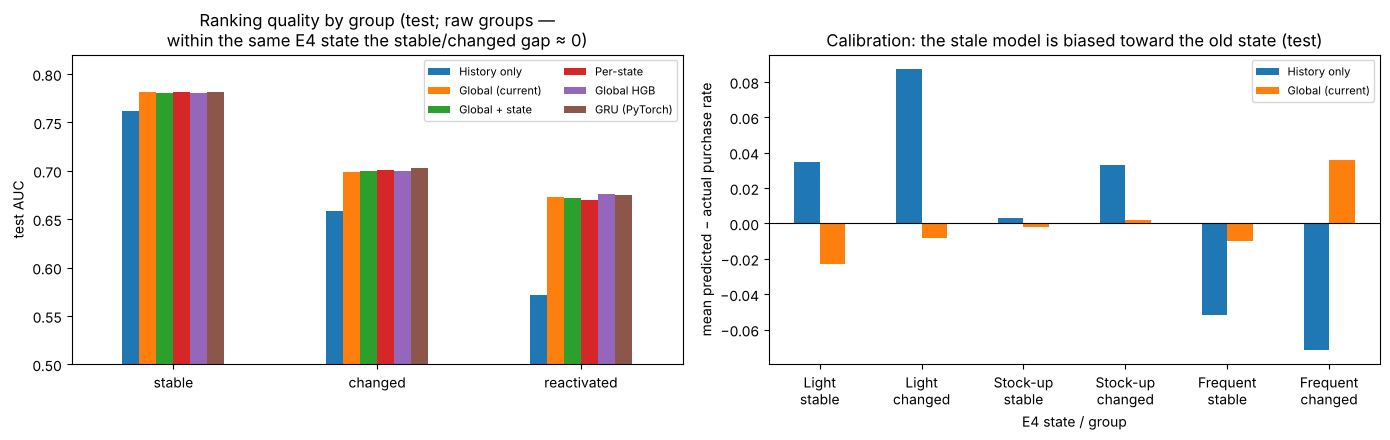

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

auc_view = test_results[test_results["group"].isin(GROUPS)].pivot(index="group", columns="model", values="AUC").reindex(GROUPS)
auc_view[MODEL_ORDER].plot.bar(ax=axes[0], rot=0)
axes[0].set(ylim=(0.5, 0.82), ylabel="test AUC", xlabel="",
            title="Ranking quality by group (test; raw groups —\nwithin the same E4 state the stable/changed gap ≈ 0)")
axes[0].legend(fontsize=8, loc="upper right", ncol=2)

cal = test_within[test_within["group"] != "reactivated"].copy()
cal["label"] = cal["E4_state"] + "\n" + cal["group"]
cal_view = cal.pivot(index="label", columns="model", values="calibration_gap")
order = [f"{s}\n{g}" for s in ACTIVE_STATES for g in ["stable", "changed"]]
cal_view = cal_view.reindex(order)[["History only", "Global (current)"]]
cal_view.plot.bar(ax=axes[1], rot=0, color=["tab:blue", "tab:orange"])
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set(ylabel="mean predicted − actual purchase rate", xlabel="E4 state / group",
            title="Calibration: the stale model is biased toward the old state (test)")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / "F_reliability.png", dpi=130)
plt.show()

### §F · Interpretation

1. **"Changed customers are harder to predict" is mostly a composition effect.** On test, AUC is 0.082 lower for changed than for stable
   customers (95% CI 0.066–0.099). Compared *within the same E4 state*, the gap is 0.008 (CI −0.012 to 0.030), statistically
   indistinguishable from zero. Stable customers are easier to rank largely because the stable group contains very different kinds of
   customers (always-Frequent and always-Light), not because their purchases are more predictable.
2. **A model that has not seen the change is genuinely less reliable after it.** The history-only ("stale") model loses an extra 0.022 AUC on
   changed customers (CI 0.008–0.034) and is **biased in the direction of the old state**: it under-predicts customers who just became
   Frequent by ≈ 7 points and over-predicts those who just became Light by ≈ 9 points (both CIs exclude 0). This is the clearest
   evidence in the project of a model failing when behavior changes.
3. **Seeing current behavior fixes most of it; explicit states add almost nothing.** The global model with E4 features removes the
   AUC loss and the "became Light" bias. Adding state labels (pooled or per-state) or using boosting changes AUC by ≤ 0.002. The one
   consistent benefit of state labels is calibration for **reactivated** customers (gap 0.022 → 0.004 on validation and test) —
   the group created by the sample's E4 selection.
4. **Not everything is fixed (validation and test disagree).** On test the current model *over*-predicts customers who just became Frequent
   by ≈ 4 points (CI 0.019–0.057), although validation showed ≈ 0. This bias is half the size of the stale model's and of opposite sign —
   the current model leans toward the *new* state slightly too much for this group. The GRU shows the same bias (≈ +3 pp, CI 0.013–0.051),
   so it is not a limitation of logistic regression: something about newly-Frequent customers is not visible in four months of behavior.
5. **A learned sequence model (PyTorch GRU) gives a small but real gain.** On test it improves AUC by ≈ 0.002 overall and ≈ 0.004 for
   changed customers (bootstrap CIs exclude 0), is stable across 5 random seeds, and calibrates reactivated customers as well as the
   state-aware model — without being given state labels. Reading the months *in order* captures a little more of the trajectory than
   hand-built averages; the size of the gain (third decimal) confirms that most of the signal is simply in recent behavior.
6. **Reactivated customers are the least predictable** for every model (test AUC ≈ 0.67 vs 0.78 for stable): they have the least recent
   history and are a selection artifact of the E4 sampling.

**Answer to the research question.** Recognizing that behavior has changed matters a lot — a model built on an outdated profile is
measurably biased toward who the customer used to be. But in this data, an *explicit discrete state* adds little once the model already sees
the latest continuous behavior. States are most useful here as a **diagnostic lens** (which customers are affected, in which direction) rather
than as a modeling component. This is a negative result for "state-aware models are more reliable", and a positive one for "behavioral change
causes predictable model failure that can be described in terms of states".

**Connection to notebook 04.** The "adaptive" targeting model (with recent-period features) beat the "static" profile at mid budgets but did not
improve overall ranking. §F gives a consistent explanation: recent behavior removes bias for customers who changed, while the gain for
everyone else is small.

**Limitations**
- One outcome window, one campaign, control customers only; P(Y | X) could not be compared across periods (there is only one outcome).
- Groups are defined by the E3→E4 transition only; longer histories of change were not modeled.
- The per-state model has only three states; with more or finer states, per-state models might behave differently (but would have less data each).
- Bootstrap intervals cover sampling variation of test customers, not variation from re-fitting the models or re-defining the states.

## §H · Bridge to formal state-transition modeling

**What this project built** (notebooks 02–03):

| Component | What we have | How it was obtained |
|---|---|---|
| States | 4 behavioral states (Inactive, Light, Stock-up, Frequent) | rule + KMeans on interpretable features, fit on train |
| Transitions | empirical transition probabilities between states | counted from observed sequences (02 §C) |
| Guards | readable conditions under which a switch is likely | shallow decision trees on time-*t* features (§E) |
| Noise handling | boundary margin and a hysteresis-style threshold | distance to cluster centers (02 §C) |
| Per-state models | per-state and state-aware purchase models | logistic regression (§F) |

Together this is an **empirical finite-state transition system**: a small set of states, a transition matrix, and statistical rules for when
transitions happen.

**What it is not.** It is not a formally specified or verified automaton:
- the guards are probabilistic tendencies with error rates (AUC ≈ 0.68), not logical conditions that hold whenever a transition occurs;
- there are no temporal semantics — rules relate one month to the next, and cannot express "for two consecutive months" or "eventually";
- nothing guarantees that the rules are mutually consistent or cover every case;
- states, transitions and per-state models were learned in separate steps, not jointly.

**Where the formal research begins** (the TU Dortmund project "Learning Verifiable State-Transition Models for Evolving Time Series"):
1. **Express guards in a temporal logic** (e.g. Signal Temporal Logic): "trips stay ≤ 2 for two consecutive periods ⇒ move to Light" instead of a single-month threshold.
2. **Learn a compact automaton consistent with observed sequences** (classical automata learning or SMT-based synthesis), rather than counting transitions between pre-defined clusters.
3. **Check learned conditions formally** — consistency, completeness, and whether candidate rules from a statistical learner actually hold.
4. **Model noise and uncertainty explicitly** — probabilistic transitions, and drift tests robust to sparse observations (§D showed why this matters).
5. **Learn states and per-state models jointly**, so that states are defined by what changes the downstream model, not only by behavior.

**Lessons from this project that motivate those steps**
- A large share of state switches is boundary noise (02 §C); a formal model needs an explicit notion of robustness, not raw label changes.
- Drift measures can be confounded by observation depth (02 §D); detected "changes" need uncertainty-aware tests.
- The model failure that matters is staleness after a real change (§F); states are most useful for diagnosing *who* is affected and in which direction.